# Исследование согласованности методов классификации MI и детекции OOD. 
## Cross-session эксперимент (rest как OOD)

Для анализа использовались 6 датасетов (в сумме 130 участников)
* BNCI2014_001 — 9 участников (https://bnci-horizon-2020.eu/database/data-sets)
* Zhou2016 — 4 участника (https://doi.org/10.6084/m9.figshare.2061654)
* Zhou2020 — 20 участников (https://doi.org/10.21227/f1c7-7x89)
* TTK 2022— 6 участников из 9, для которых есть сессии в разные дни (https://repo.researchdata.hu/dataset.xhtml?persistentId=hdl:21.15109/CONCORDA/UOQQVK)
* Wang2026 — 29 участников (https://doi.org/10.1184/R1/32293995)
* Stieger2021 — 62 участника (https://doi.org/10.6084/m9.figshare.13123148)

Были выбраны датасеты, в которых несколько сессий, есть классы right_hand, left_hand, rest (или можно извлечь аналог rest).
В датасетах Zhou2020, Stieger2021, Wang2026 берутся размеченные пробы rest, в TTK аннотация "Stimulus/S 1". В датасетах Zhou2016 пробы с rest вырезались в интервале 5.5–8.5 с после MI-события, в BNCI2014_001 нарезались 3-секундные окна с шагом 3с из калибровочной записи с открытыми глазами.

Для анализа использовался интервал 3 сек., данные были приведены к частоте 250 Гц, использовались данные с 7 электродов, которые есть во всех датасетах ("FC3", "FCz", "FC4", "C3", "C4", "CP3", "CP4"). Применена фильтрация 8–32 Гц.

Обучение проводилось только на классах right_hand/left_hand. Для детекции OOD использовался класс rest.

### Cross-session: Обучение проводилось на первой сесии, тест проводился на второй сессии. 

Проверялись следующие методы
| Классификация MI | Детекция OOD |
|---|---|
| ACM+TS+SVM | ACM+TS+OCSVM |
| FBCSP+ElasticNet | FBCSP+IsolationForest |
| Log-bandpower+shLDA | Log-bandpower+Mahalanobis |
| Microstates+GB | Microstates+LOF |
| VAR+shLDA | VAR+Mahalanobis |
| ShallowConvNet | ShallowConvNet+kNN |
| EEGNet | EEGNet+TempDens (адаптация метода [Liu et al. (2026)](https://arxiv.org/abs/2605.01014)) |


Для каждого участника и каждого метода записывались
* Balanced accuracy и ROC AUC для классификации: MI_BA, MI_AUROC
* ROC AUC для детекции OOD

Данные по всем участникам: [cross-session_7-channels-rest.csv](./results/cross-session_7-channels-rest.csv)

## Проверяемые гипотезы: 
* H1: разные MI-классификаторы согласованно ранжируют участников по качеству классификации.
* H2: разные OOD-детекторы согласованно ранжируют участников по качеству детекции.
* H3: участники с более высоким качеством MI-классификации имеют более высокое качество OOD-детекции.


Код: 
- [pipelines.py](./pipelines.py) -- Пайплайны
- [methods.py](./methods.py) -- Методы, используемые в пайплайнах
- [processing.py](./processing.py) -- Загрузка и обработка данных, обучение и расчет метрик
- [analysis.py](./analysis.py) -- Вспомогательные функции для анализа
- [experiment_cross-session_7ch.ipynb](./experiment_cross-session_rest.ipynb) -- Запуск эксперимента

In [1]:
from pathlib import Path
from analysis import *
import pipelines as p
from processing import create_exp_file, display_summary_by_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy.stats import bootstrap, permutation_test, spearmanr
from IPython.display import display

EXPERIMENT = "cross-session_7-channels-rest"
DATASETS = [ "Zhou2016", "BNCI2014_001", "TTK", "Zhou2020", "Wang2026_45", "Stieger2021_fix"   ]
MI_METHODS = ['ACM+TS+SVM', 'FBCSP+ElasticNet', 'ShallowConvNet', 'EEGNet', "Microstates+GB", "VAR+shLDA", "Log-bandpower+shLDA" ]
OOD_METHODS = ['ACM+TS+OCSVM', 'FBCSP+IsolationForest', 'ShallowConvNet+kNN', 'EEGNet+TempDens', "Log-bandpower+Mahalanobis", "Microstates+LOF", "VAR+Mahalanobis" ]
MI_METRICS = ("MI_BA", "MI_AUROC")

RESULTS = Path( "results" )
filename = create_exp_file(EXPERIMENT, res_path=RESULTS)

/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/optuna/integration/sklearn.py:14: FutureWarning: `optuna.integration.sklearn` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `optuna_integration.sklearn` instead.
  optuna_warn(f"{msg} Use `optuna_integration.sklearn` instead.", FutureWarning)
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/braindecode/models/eegpt.py:497: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/braindecode/models/eegpt.py:1452: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = make_standard_montage("standard_1020")


Saved to results/cross-session_7-channels-rest.csv


## Средние результаты по методам
MI balanced accuracy, MI AUROC, OOD AUROC


In [2]:
data = pd.read_csv(filename)
data = data[data["dataset"].isin(DATASETS) & ((data["experiment_type"].eq("mi") & data["method"].isin(MI_METHODS)) | (data["experiment_type"].eq("ood") & data["method"].isin(OOD_METHODS)))].copy()


scores = data.melt(
    id_vars=["dataset", "subject", "method"],
    value_vars=["MI_BA", "MI_AUROC", "OOD_AUROC"],
    var_name="metric",
    value_name="score",
).dropna(subset=["score"])

wide = scores.pivot(
    index=["dataset", "subject"],
    columns=["metric", "method"],
    values="score",
).dropna().round(12)

display_summary_by_dataset( EXPERIMENT, MI_METHODS, OOD_METHODS, datasets=DATASETS )

## Согласованность методов: MI BA, MI AUROC и OOD

Проверяем, согласованно ли методы ранжируют участников одного датасета. 

Используем коэффициент согласованности Кендалла W.

W = 1 -- полное совпадение ранжирований, 0 -- отсутствие согласованности.

Перестановочный тест проверяет, выражено ли общее ранжирование сильнее, чем при случайном сопоставлении участников между методами.

### По датасетам

In [3]:
rows = []
for (metric, dataset), group in scores.groupby(["metric", "dataset"]):
    x = group.pivot(index="subject", columns="method", values="score").dropna().round(12)
    test = permutation_test(tuple(x.rank().to_numpy().T), lambda *r, axis: np.square(np.sum(r, axis=0)).sum(axis=axis), permutation_type="pairings", alternative="greater", n_resamples=9999, batch=256, rng=42)
    rows.append({"metric": metric, "dataset": dataset, "n": len(x), "W": pg.friedman(x.T)["W"].iloc[0], "p_perm": test.pvalue})

agreement = pd.DataFrame(rows)
display(agreement.set_index(["metric", "dataset"]).round(4))


n       W  p_perm
metric    dataset                            
MI_AUROC  BNCI2014_001      9  0.9082  0.0001
          Stieger2021_fix  62  0.6871  0.0001
          TTK               6  0.6408  0.0001
          Wang2026_45      29  0.6851  0.0001
          Zhou2016          4  0.6245  0.0012
          Zhou2020         20  0.7300  0.0001
MI_BA     BNCI2014_001      9  0.8997  0.0001
          Stieger2021_fix  62  0.6033  0.0001
          TTK               6  0.8161  0.0001
          Wang2026_45      29  0.5970  0.0001
          Zhou2016          4  0.4939  0.0117
          Zhou2020         20  0.6058  0.0001
OOD_AUROC BNCI2014_001      9  0.6043  0.0001
          Stieger2021_fix  62  0.5195  0.0001
          TTK               6  0.6175  0.0001
          Wang2026_45      29  0.4492  0.0001
          Zhou2016          4  0.9184  0.0001
          Zhou2020         20  0.5560  0.0001

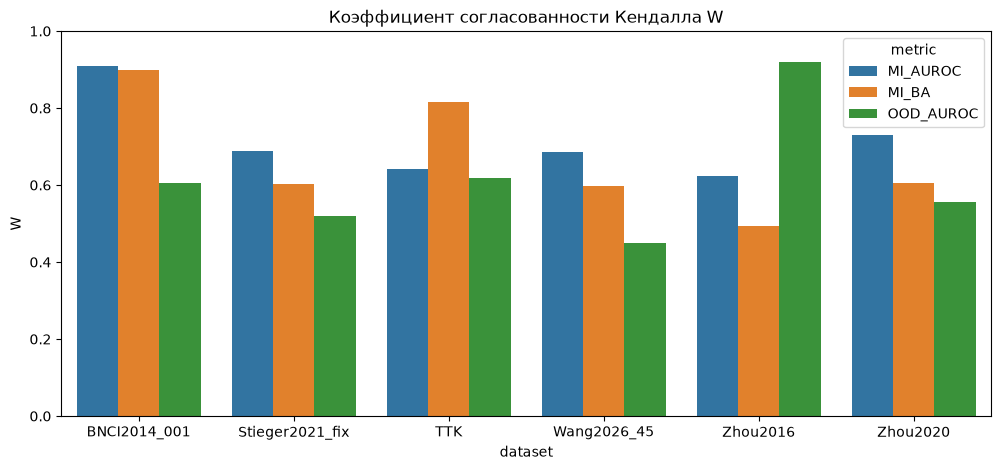

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.barplot(data=agreement, x="dataset", y="W", hue="metric", errorbar=None)
plt.title("Коэффициент согласованности Кендалла W")
plt.ylim(0, 1)
plt.show()

### По всем участникам

In [5]:
rows = []
for metric in [*MI_METRICS, "OOD_AUROC"]:
    rows.append({"metric": metric, "n": len(wide), "W": pg.friedman(wide[metric].reset_index(drop=True).T)["W"].iloc[0]})

agreement_all = pd.DataFrame(rows).set_index("metric")
display(agreement_all.round(4))


,n,W
metric,,
MI_BA,130,0.6697
MI_AUROC,130,0.7307
OOD_AUROC,130,0.5703


## Связь MI BA, MI AUROC с OOD AUROC

Проверяем, связаны ли средние ранги MI и OOD среди участников этого датасета.

Считается корреляция Спирмена.

Для каждого участника считается и усредняется его ранг в каждом методе, затем проверяется связь этих показателей.

Rho > 0 -- участники с более высокими результатами классификации MI обычно имеют более высокие результаты детекции OOD.

Для определения значимости используется перестановочный тест, затем применяется поправка Холма.


In [6]:
rows = []
for dataset, x in [*wide.groupby(level="dataset"), ("ALL datasets", wide)]:
    profiles = rank_profiles(x)
    ood = profiles["OOD_AUROC"].to_numpy()
    for metric in MI_METRICS:
        mi = profiles[metric].to_numpy()
        test = permutation_test((ood,), lambda y: spearmanr(mi, y).statistic, permutation_type="pairings", alternative="two-sided", n_resamples=9999, random_state=42)
        rows.append({"dataset": dataset, "metric": f"{metric} ~ OOD_AUROC", "n": len(x), "rho": test.statistic, "p_perm": test.pvalue})

association = pd.DataFrame(rows)
association["p_holm"] = pg.multicomp(association["p_perm"], method="holm")[1]
display(association.set_index(["metric", "dataset"]).round(4))


,,n,rho,p_perm,p_holm
metric,dataset,,,,
MI_BA ~ OOD_AUROC,BNCI2014_001,9,0.3096,0.4046,1.0000
MI_AUROC ~ OOD_AUROC,BNCI2014_001,9,0.3264,0.3756,1.0000
MI_BA ~ OOD_AUROC,Stieger2021_fix,62,0.2409,0.0578,0.5780
MI_AUROC ~ OOD_AUROC,Stieger2021_fix,62,0.2575,0.0398,0.4776
MI_BA ~ OOD_AUROC,TTK,6,0.1429,0.8028,1.0000
MI_AUROC ~ OOD_AUROC,TTK,6,0.0286,1.0000,1.0000
MI_BA ~ OOD_AUROC,Wang2026_45,29,0.2709,0.1566,1.0000
MI_AUROC ~ OOD_AUROC,Wang2026_45,29,0.1740,0.3646,1.0000
MI_BA ~ OOD_AUROC,Zhou2016,4,-0.8944,0.3333,1.0000


### Корреляция Спирмена с учетом принадлежности к датасету

Неопределеность оценки при повторном выборе участников внутри каждого датасета (95% bootstrap интервалы)

In [7]:
ci = bootstrap_ci(wide)
adjusted = pd.DataFrame({"n": len(wide), "rho": adjusted_rho(wide), "CI_low": ci.low, "CI_high": ci.high, "p_perm": permutation_p(wide)}, index=pd.Index(MI_METRICS, name="metric"))
display(adjusted.round(4))


,n,rho,CI_low,CI_high,p_perm
metric,,,,,
MI_BA,130,0.2595,0.0786,0.4211,0.0039
MI_AUROC,130,0.2537,0.0694,0.4213,0.0043


Средняя корреляция MI–OOD, рассчитанная отдельно в каждом датасете, с весами по числу участников

In [8]:
weighted = pd.DataFrame({"rho": weighted_rho(wide), "p_perm": permutation_p(wide, statistic=weighted_rho)}, index=pd.Index(MI_METRICS, name="metric"))
weighted["p_holm"] = pg.multicomp(weighted["p_perm"], method="holm")[1]
display(weighted.round(4))

,rho,p_perm,p_holm
metric,,,
MI_BA,0.2413,0.0067,0.0134
MI_AUROC,0.2224,0.0121,0.0134


## Средние ранги по участникам

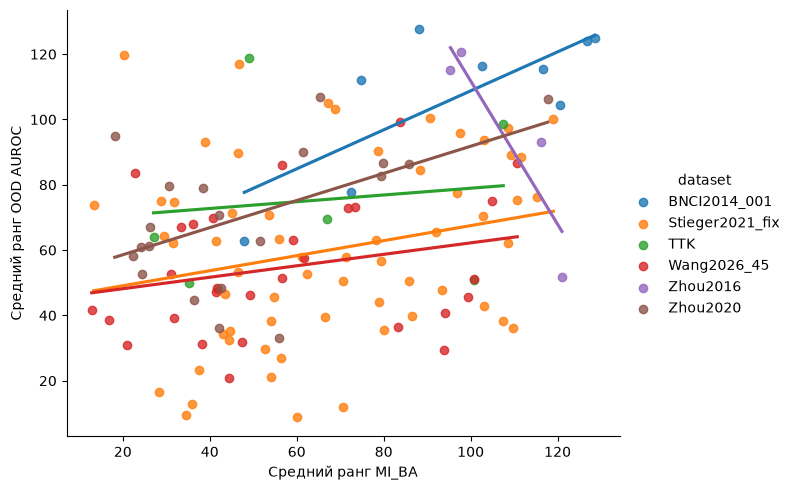

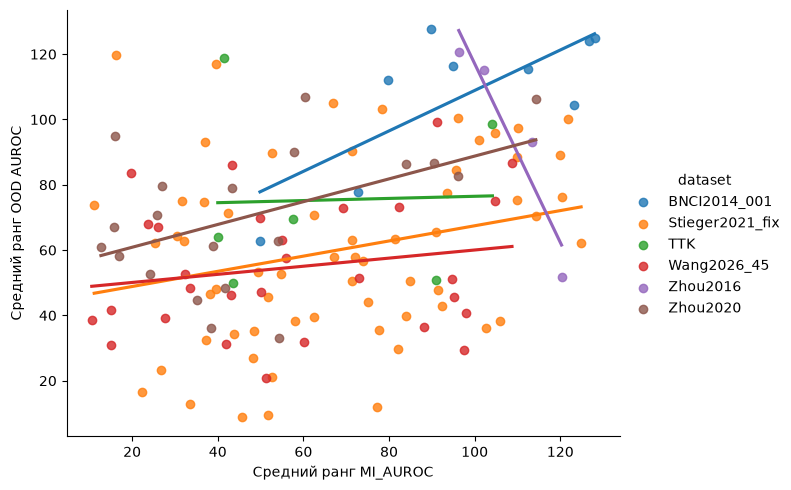

In [9]:
profiles = rank_profiles(wide).reset_index()
for metric in MI_METRICS:
    g = sns.lmplot(data=profiles, x=metric, y="OOD_AUROC", hue="dataset", ci=None, truncate=True, height=5, aspect=1.3)
    g.set_axis_labels(f"Средний ранг {metric}", "Средний ранг OOD AUROC")
    plt.show()

## Проверка устойчивости при исключении датасетов

In [10]:
rows = []
for kind, labels in [("dataset", wide.index.get_level_values("dataset").unique()), ("method", wide.columns.get_level_values("method").unique()), ("subject", wide.index)]:
    for label in labels:
        x = wide.drop(columns=label, level="method") if kind == "method" else wide.drop(index=label, level="dataset") if kind == "dataset" else wide.drop(index=[label])
        rows.append({"removed": kind, "label": str(label), **dict(zip(MI_METRICS, adjusted_rho(x)))})

sensitivity = pd.DataFrame(rows)
display(sensitivity.melt(id_vars=["removed", "label"], var_name="metric", value_name="rho").groupby(["removed", "metric"])["rho"].agg(["min", "max"]).round(3))
display(sensitivity[sensitivity["removed"].eq("dataset")].round(3))


min    max
removed metric                
dataset MI_AUROC  0.229  0.278
        MI_BA     0.235  0.310
method  MI_AUROC  0.223  0.279
        MI_BA     0.229  0.281
subject MI_AUROC  0.236  0.290
        MI_BA     0.242  0.297

,removed,label,MI_BA,MI_AUROC
0,dataset,BNCI2014_001,0.243,0.238
1,dataset,Stieger2021_fix,0.310,0.276
2,dataset,TTK,0.264,0.264
3,dataset,Wang2026_45,0.259,0.278
4,dataset,Zhou2016,0.272,0.261
5,dataset,Zhou2020,0.235,0.229


## Результат проверки гипотез

In [11]:
agreement_overall = pd.DataFrame([{"metric": metric, "dataset": "ALL weighted", **overall_agreement(wide[metric])} for metric in [*MI_METRICS, "OOD_AUROC"]])
summary = pd.concat([agreement, agreement_overall], ignore_index=True).rename(columns={"W": "effect"}).assign(coefficient="W")
summary = pd.concat([summary, adjusted.reset_index().rename(columns={"rho": "effect"}).assign(dataset="ALL adjusted", coefficient="rho")], ignore_index=True)
summary["hypothesis"] = np.where(summary["coefficient"].eq("rho"), "H3: MI–OOD association", np.where(summary["metric"].eq("OOD_AUROC"), "H2: OOD agreement", "H1: MI agreement"))
summary["p_holm"] = pg.multicomp(summary["p_perm"], method="holm")[1]
summary["significant"] = summary["p_holm"] < 0.05
display(summary.loc[summary["dataset"].isin(["ALL weighted", "ALL adjusted"]), ["hypothesis", "metric", "dataset", "n", "coefficient", "effect", "p_perm", "p_holm", "significant"]].round(4))

,hypothesis,metric,dataset,n,coefficient,effect,p_perm,p_holm,significant
18,H1: MI agreement,MI_BA,ALL weighted,130,W,0.6293,0.0001,0.0023,True
19,H1: MI agreement,MI_AUROC,ALL weighted,130,W,0.7045,0.0001,0.0023,True
20,H2: OOD agreement,OOD_AUROC,ALL weighted,130,W,0.5321,0.0001,0.0023,True
21,H3: MI–OOD association,MI_BA,ALL adjusted,130,rho,0.2595,0.0039,0.0117,True
22,H3: MI–OOD association,MI_AUROC,ALL adjusted,130,rho,0.2537,0.0043,0.0117,True


## Корреляции отдельных методов по участникам

Корреляции Спирмена. 

Столбцы и строки отсортированы по BA/AUROC методов.

### По всем участникам

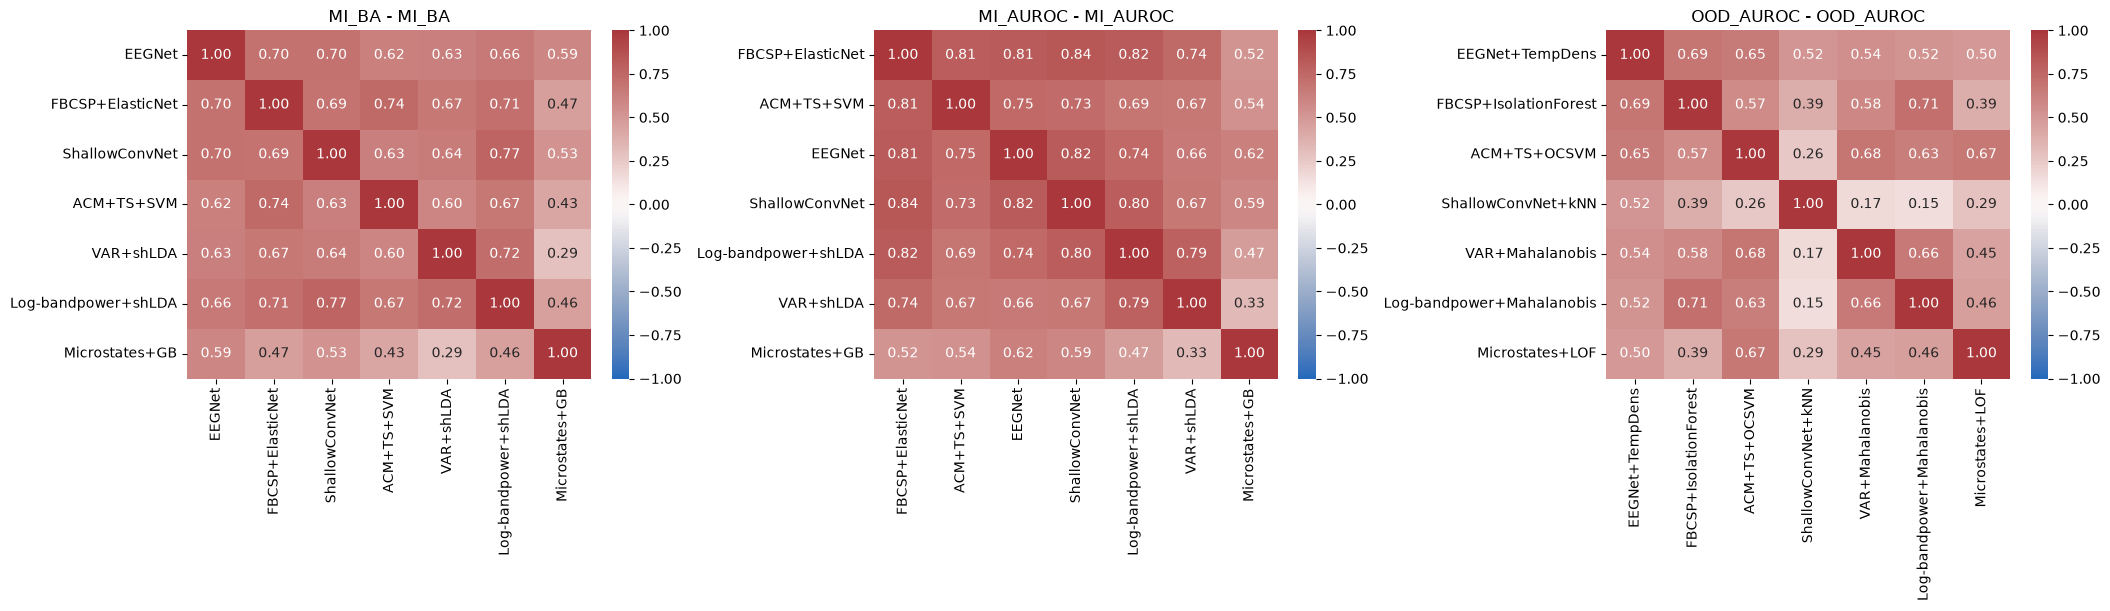

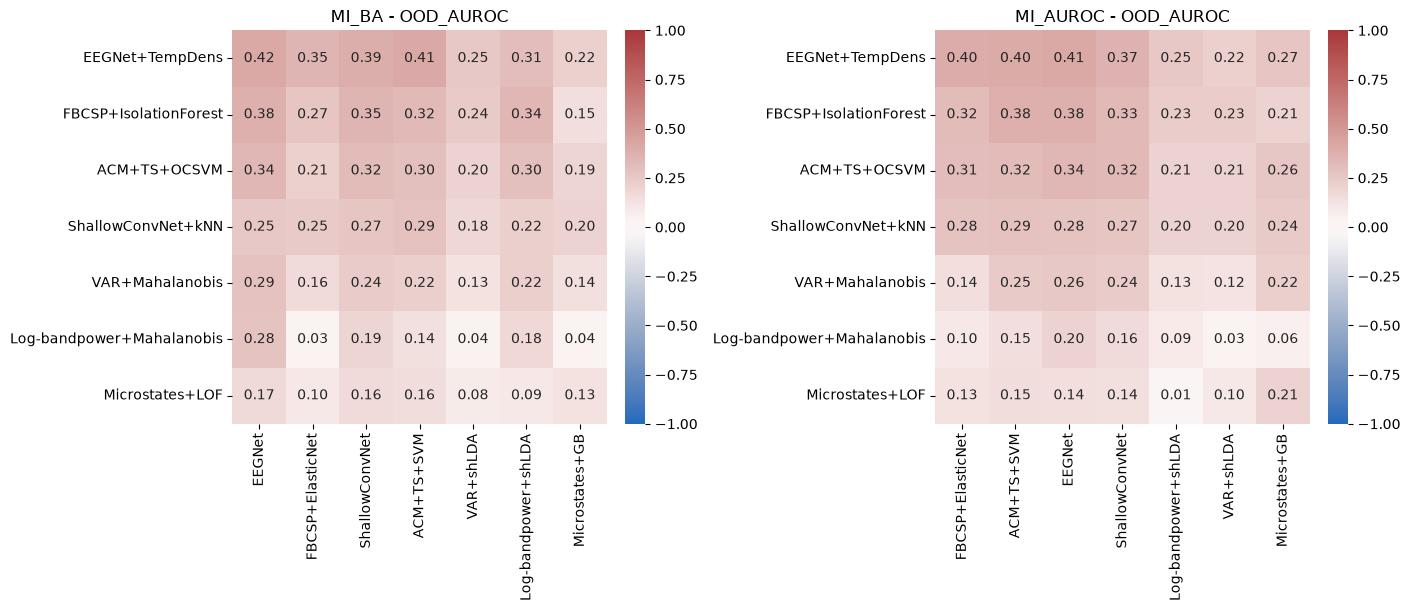

In [12]:
corr = wide.corr(method="spearman")

within = [(m, m) for m in [*MI_METRICS, "OOD_AUROC"]]
between = [("OOD_AUROC", m) for m in MI_METRICS]

for panels in [within, between]:
    fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 6), layout="constrained")
    for ax, (a, b) in zip(axes, panels):
        matrix = corr.xs(a).xs(b, axis=1)
        matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
        ax.set(title=f"{b} - {a}", xlabel="", ylabel="")
    plt.show()

### Взвешенное среднее по датасетам

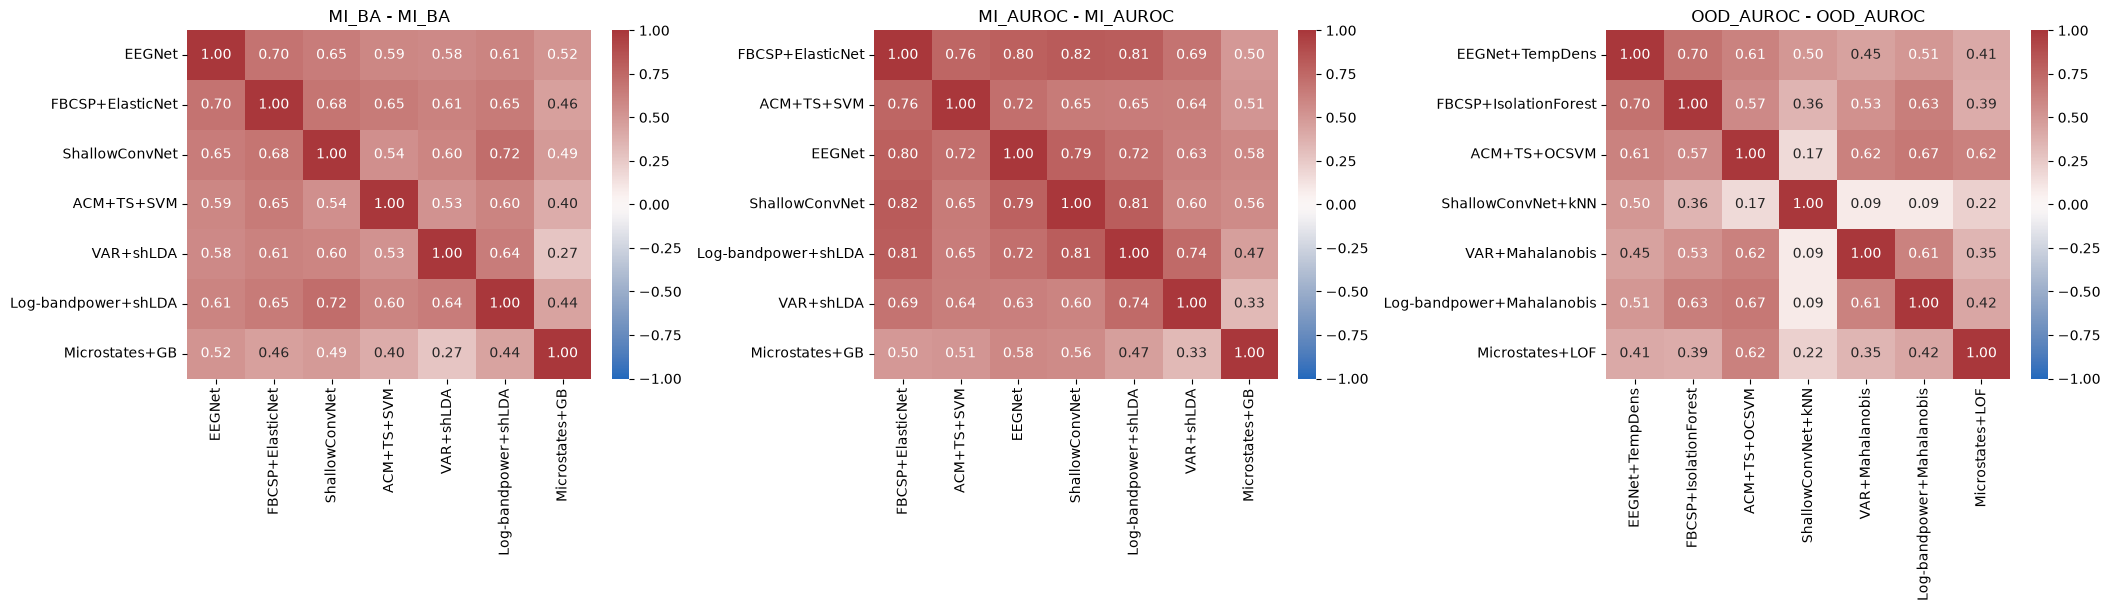

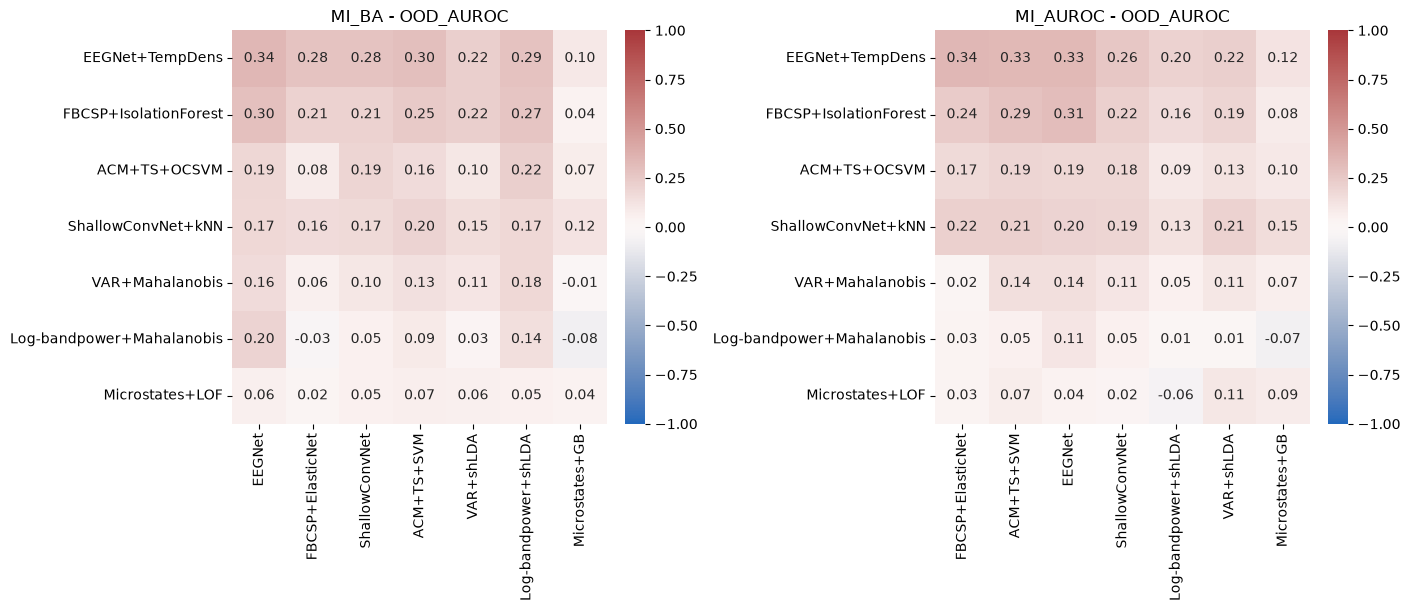

In [13]:
parts = [x for _, x in wide.groupby(level="dataset") if len(x) >= 3]
corr_within = pd.DataFrame(np.average([x.corr(method="spearman").to_numpy() for x in parts], axis=0, weights=[len(x) for x in parts]), index=wide.columns, columns=wide.columns)

within = [(m, m) for m in [*MI_METRICS, "OOD_AUROC"]]
between = [("OOD_AUROC", m) for m in MI_METRICS]

for panels in [within, between]:
    fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 6), layout="constrained")
    for ax, (a, b) in zip(axes, panels):
        matrix = corr_within.xs(a).xs(b, axis=1)
        matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
        ax.set(title=f"{b} - {a}", xlabel="", ylabel="")
    plt.show()


Корреляции между методами

In [14]:
rows = []
for metric in MI_METRICS:
    r = corr_within.xs("OOD_AUROC").xs(metric, axis=1).to_numpy().ravel()
    rows.append({"metric": metric, "median_rho": np.median(r), "min_rho": r.min(), "max_rho": r.max(), "positive_pairs": int((r > 0).sum()), "pairs": r.size})
display(pd.DataFrame(rows).set_index("metric").round(3))

,median_rho,min_rho,max_rho,positive_pairs,pairs
metric,,,,,
MI_BA,0.152,-0.079,0.338,46,49
MI_AUROC,0.129,-0.071,0.343,47,49


## Результаты по участникам

Строки упорядочены по медиане MI BA, столбцы упорядочены по BA/AUROC.

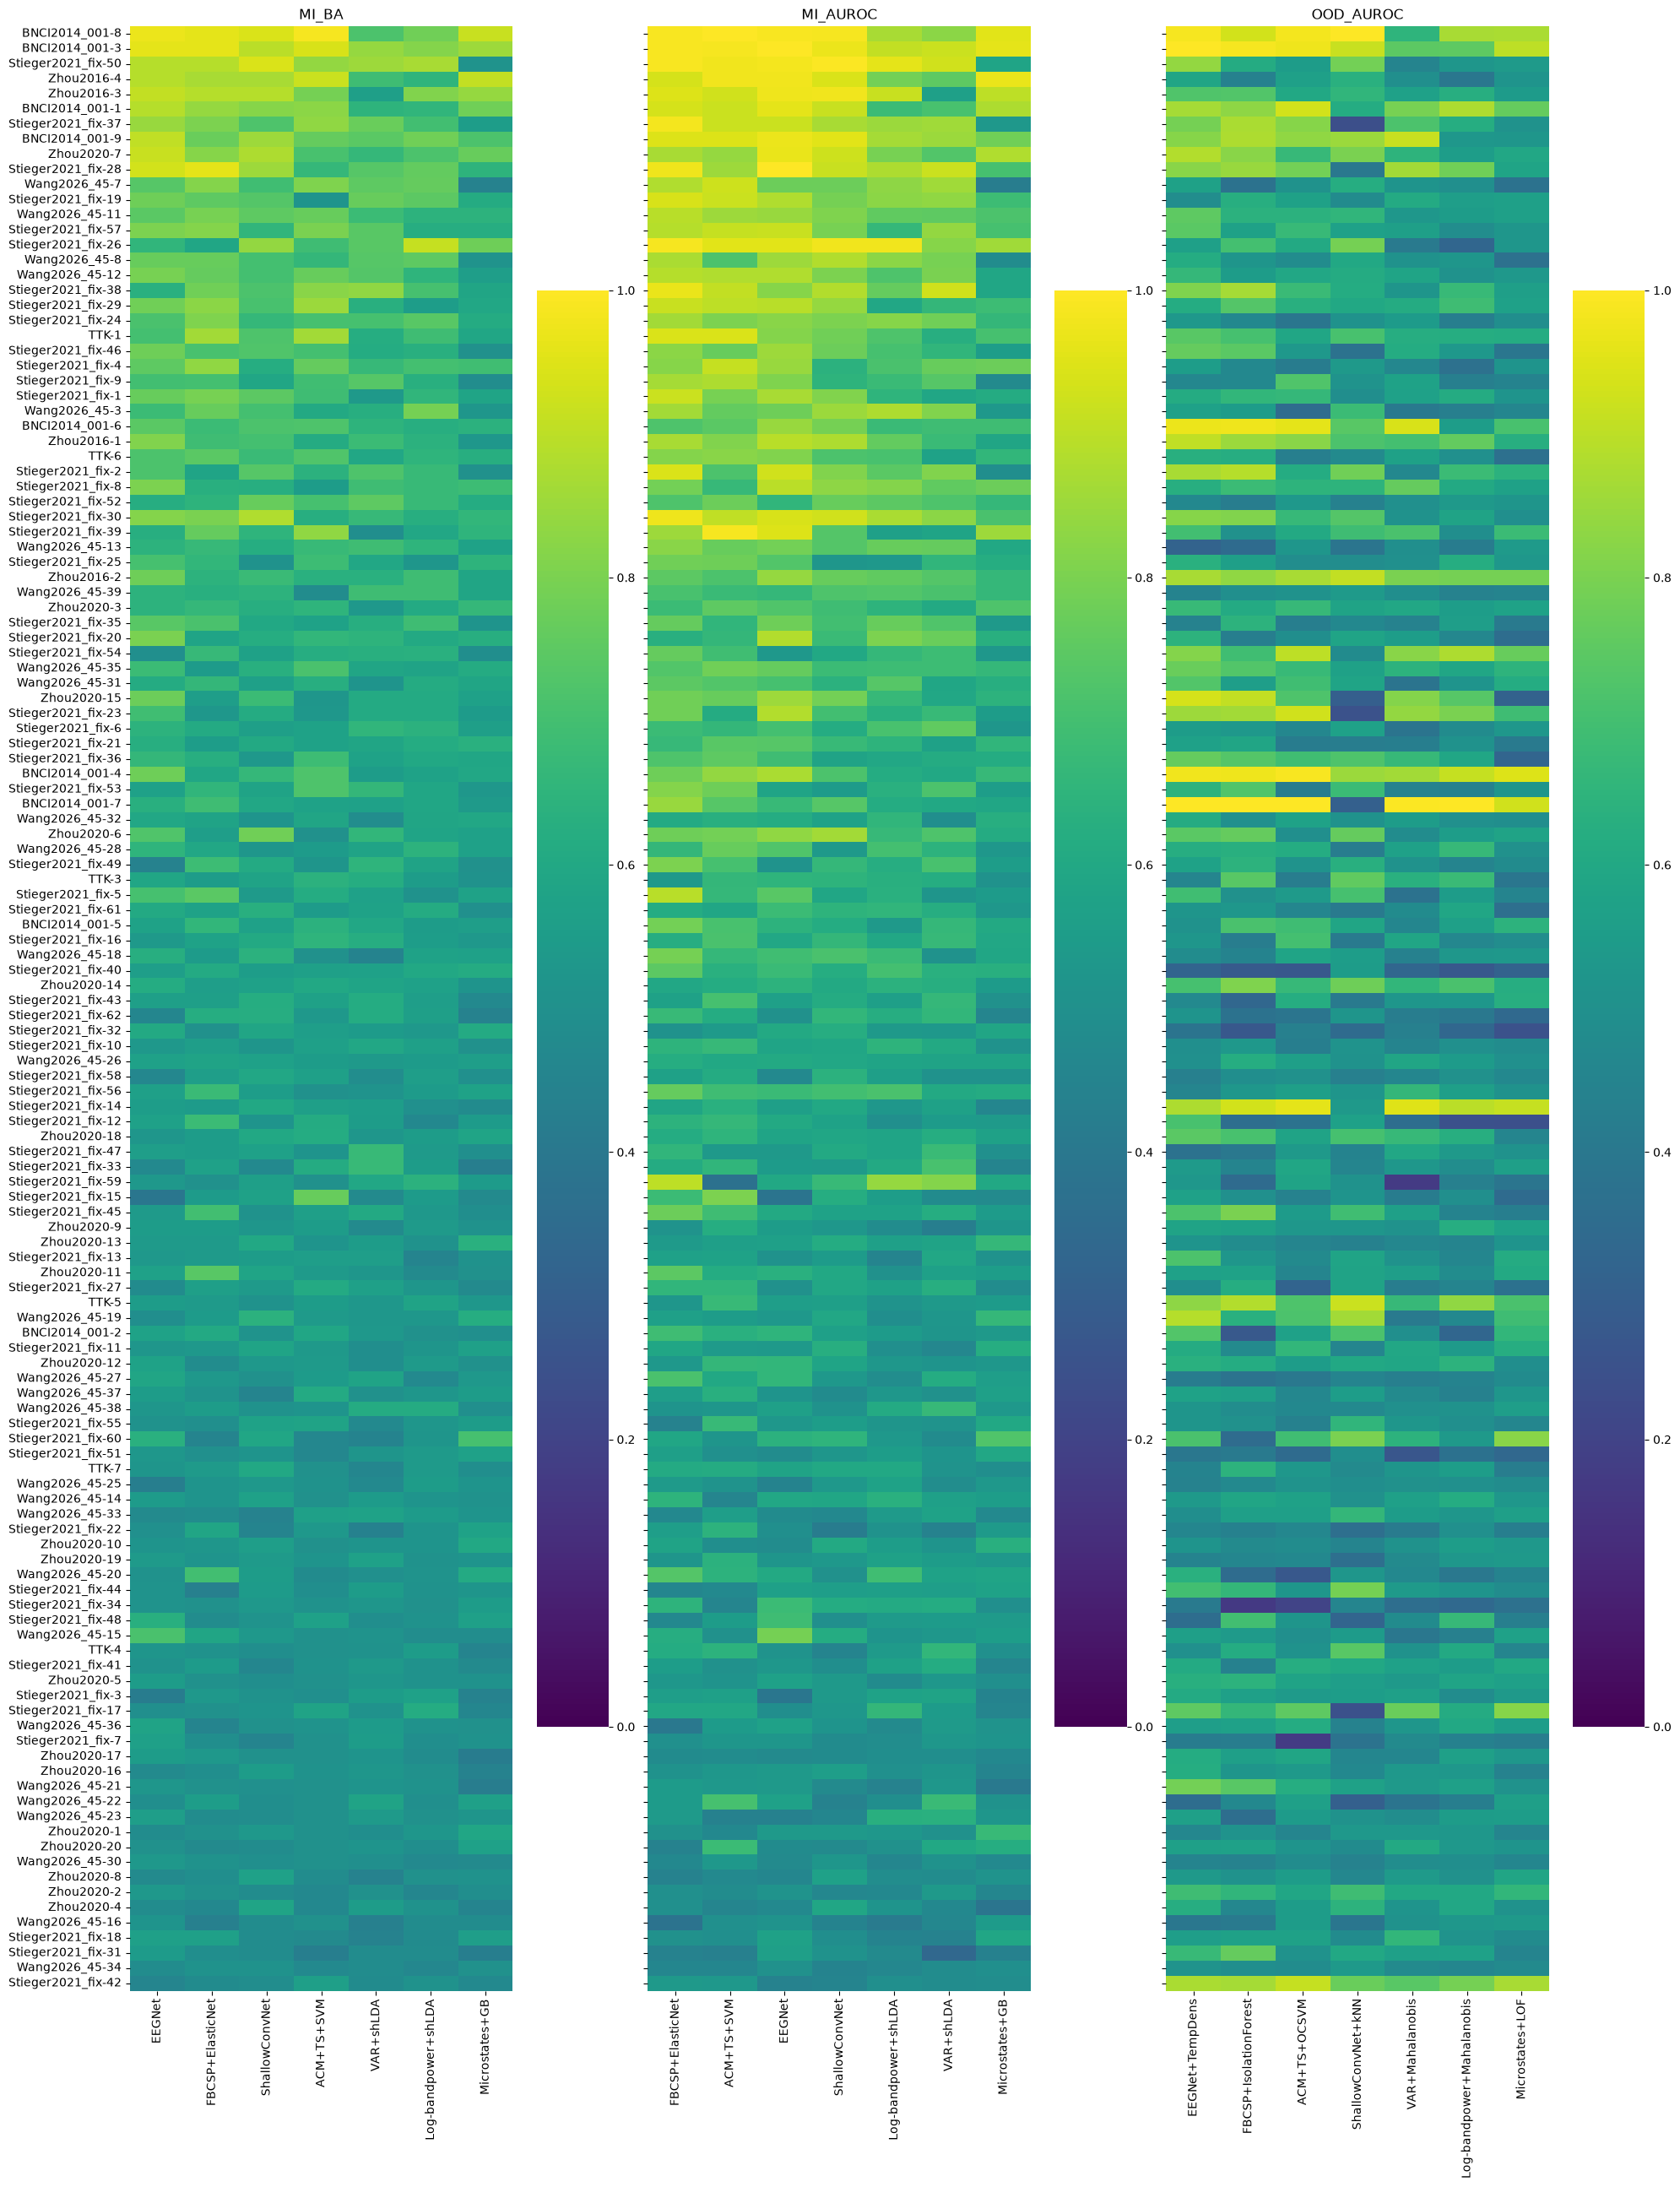

In [15]:
ordered = wide.loc[wide["MI_BA"].median(axis=1).sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 3, figsize=(20, max(6, len(wide) * .2)), sharey=True)
for ax, metric in zip(axes, ["MI_BA", "MI_AUROC", "OOD_AUROC"]):
    t = ordered[metric]
    t = t.loc[:, t.mean().sort_values(ascending=False).index]
    sns.heatmap(t, ax=ax, cmap="viridis", vmin=0, vmax=1, yticklabels=True)
    ax.set(title=metric, xlabel="", ylabel="")
    ax.tick_params(axis="y", labelleft=ax is axes[0])
plt.tight_layout()
plt.show()

## Распределения всех сочетаний методов внутри участников

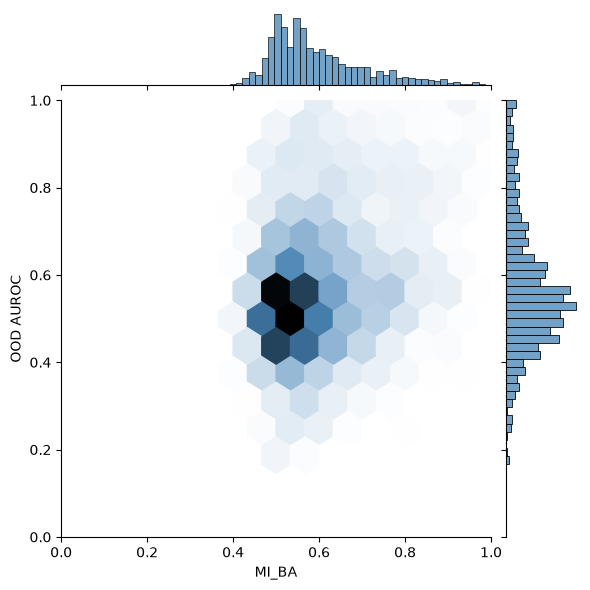

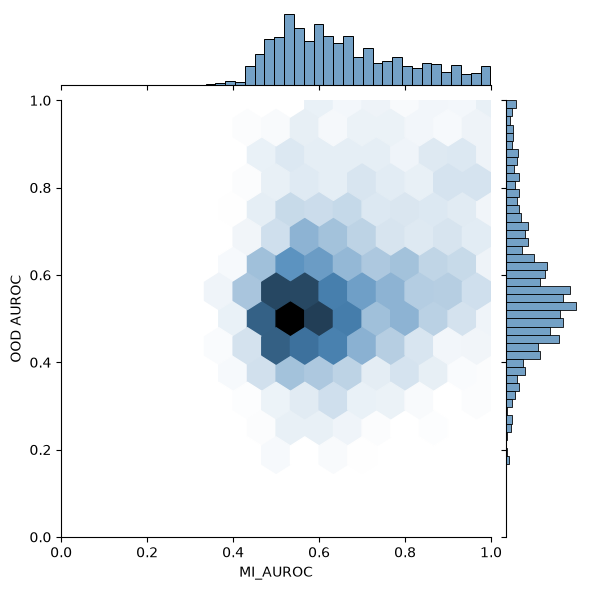

In [16]:
ood_long = wide["OOD_AUROC"].stack().rename("OOD").reset_index()
for metric in MI_METRICS:
    pairs = wide[metric].stack().rename("MI").reset_index().merge(
        ood_long, on=["dataset", "subject"])
    g = sns.jointplot(data=pairs, x="MI", y="OOD", kind="hex", height=6,
                      xlim=(0, 1), ylim=(0, 1), gridsize=15,
                      extent=(0, 1, 0, 1), mincnt=1, color="steelblue")
    g.set_axis_labels(metric, "OOD AUROC")
    plt.show()